# Week 5 - Transfer Learning

**Name:** Zubeda Raheem

**Subject:** Introduction to Applied AI

**Project:** Project 2: Deep Learning Applications

In [8]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda

# Auto-find the folders that directly contain the 6 class folders
def find_dir(name):
    for root, dirs, files in os.walk('/kaggle/input'):
        if os.path.basename(root) == name and 'forest' in dirs:
            return root

TRAIN_DIR = find_dir('seg_train')
TEST_DIR = find_dir('seg_test')
print('TRAIN_DIR:', TRAIN_DIR)
print('TEST_DIR: ', TEST_DIR)

classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
TRAIN_DIR: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
TEST_DIR:  /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


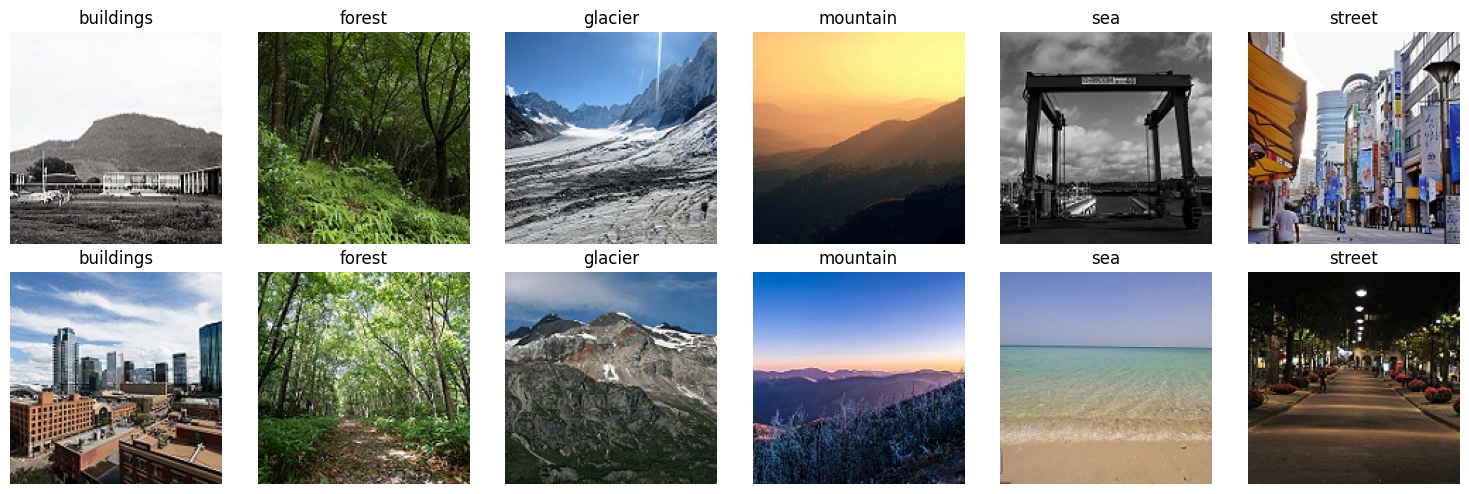

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [9]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

# Part 1:

## 1. Dataset and Class Counts
The dataset is Intel Image Classification with 6 scene classes.

| Class | Train | Test |
|---|---|---|
| buildings | 2191 | 437 |
| forest | 2271 | 474 |
| glacier | 2404 | 553 |
| mountain | 2512 | 525 |
| sea | 2274 | 510 |
| street | 2382 | 501 |
| **Total** | **14,034** | **3,000** |

The classes are fairly balanced, so accuracy is a reasonable metric.

## 2. An Image as Numbers
- **Shape (H, W, C):** (150, 150, 3), meaning 150 pixels high, 150 pixels wide, and 3 colour channels (red, green, blue)
- **Data type:** uint8
- **Value range:** 0 to 255
- **Red channel, top-left 3x3:** values between 3 and 8, so that corner is very dark

## 3. Most Similar Classes by Eye
- **Glacier and mountain:** both show snow, rock, and sky in similar scenes.
- **Buildings and street:** both contain city scenes.

## 4. My Prediction (checked in Part 6)
The model will confuse **glacier with mountain** the most, because their colours, textures, and scenery overlap the most. I will compare this with the confusion matrix in Part 6.

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


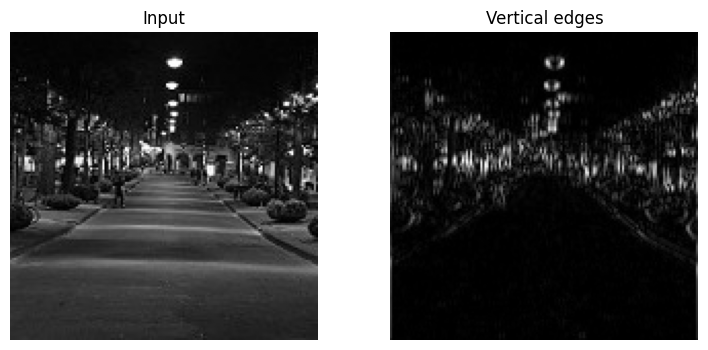

In [20]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

In [10]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64 : {count(conv):,} parameters')   # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')   # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64 : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


# Part 2:

## 1. Convolution Check
The 5x5 vertical-edge example gave three rows of [30, 30, 0], as expected.
- Window on columns 0 to 2 of a row [0, 0, 10, 10, 10]: (-1×0) + (0×0) + (1×10) = 10 per row, and 3 rows give **30**
- Window on columns 1 to 3: (-1×0) + (0×10) + (1×10) = 10 per row, so **30**
- Window on columns 2 to 4: (-1×10) + (0×10) + (1×10) = 0, so **0**

The output is 3x3 because (5 - 3 + 0) / 1 + 1 = 3. On the real photo (a night street scene converted to grayscale), the kernel highlighted vertical edges such as tree trunks, lamp posts and building sides, and left flat areas such as the road and the sky dark. This is because the kernel [-1, 0, 1] responds only where brightness changes from left to right.

## 2. Parameter Counts
- **Conv 3x3, 3 → 64:** (K × K × C_in + 1) × C_out = (3 × 3 × 3 + 1) × 64 = 28 × 64 = **1,792**
- **Dense 67,500 → 512:** 150 × 150 × 3 = 67,500 inputs, so 67,500 × 512 + 512 = 34,560,000 + 512 = **34,560,512**
- **Ratio:** 34,560,512 / 1,792 = **19,286**, so the dense layer needs 19,286 times more parameters.

## 3. Output Sizes (W = 224, K = 3, P = 1)
- **Stride 1:** (224 - 3 + 2) / 1 + 1 = **224**, so the output is (1, 64, 224, 224)
- **Stride 2:** (224 - 3 + 2) / 2 + 1 = 111.5 → 111 + 1 = **112**, so the output is (1, 64, 112, 112)
- **2x2 max pool:** 224 / 2 = **112**, with the 3 channels unchanged: (1, 3, 112, 112)

## 4. Why Weight Sharing Helps
A convolution reuses the same small kernel at every position, so the model needs only a few weights, not a separate weight for every pixel. Because the same detector scans the whole image, it recognises an edge or object wherever it appears, so the model does not need to relearn it for each location.

In [11]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


#  Part 3:

## 1. Split Sizes
| Split | Images | Transform |
|---|---|---|
| Train | 11,929 | augmented |
| Validation | 2,105 | clean (resize + normalize only) |
| Test | 3,000 | clean (resize + normalize only) |

The 14,034 training images were split 85% / 15% with the same random indices on both views of the folder, so no image is in both train and validation (11,929 + 2,105 = 14,034).

## 2. Augmentation That Would Be Wrong
- **For this scene dataset:** a vertical flip. Scenes have a natural up/down order (sky on top, ground or sea below), so an upside-down image does not look like a real photo of its class. A strong hue shift would also be wrong, because colour is a key cue (blue sea, green forest, white glacier).
- **For handwritten digits:** a horizontal flip or a 180° rotation. A flipped 2, 3, 5, or 7 is no longer a valid digit, and a 6 rotated by 180° looks like a 9, so the label would become wrong.

The rule: an augmentation is only valid if the transformed image still truly belongs to the same label.

## 3. Why a Separate Validation Set
The validation set chooses the best epoch and compares feature extraction with fine-tuning. The test set must play no part in any choice, so it can give an honest final estimate.

## 4. Why Augmentation Is on Training Data Only
Augmentation makes training images harder and more varied so the model generalises. Validation and test must be clean so they measure performance on real, unmodified images.

In [12]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                      # forward pass
            loss = F.cross_entropy(logits, yb)      # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                     # backpropagation
                optimizer.step()                    # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)    # keep the best validation epoch
    return best_acc

In [13]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                          # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))   # new 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (32s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (32s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (32s)
Best validation accuracy, feature extraction: 0.901


# Part 4:

## 1. Trainable Parameters
Only the new classification head was trained: **3,078** of **11,179,590** parameters (512 × 6 weights + 6 biases = 3,072 + 6). That is 3,078 / 11,179,590 ≈ **0.03%** of the network. The rest of ResNet-18 was frozen.

## 2. Validation Accuracy per Epoch
| Epoch | Train loss | Train acc | Val loss | Val acc |
|---|---|---|---|---|
| 1 | 0.588 | 0.809 | 0.327 | 0.894 |
| 2 | 0.326 | 0.890 | 0.290 | 0.899 |
| 3 | 0.299 | 0.895 | 0.276 | 0.901 |

**Best validation accuracy (feature extraction): 0.901.** Both losses fell steadily, so the model was still improving and showed no sign of overfitting.

## 3. Why High Accuracy with So Few Trainable Parameters
ResNet-18 was pretrained on 1.2 million ImageNet photos, so its frozen layers already detect a hierarchy of features: edges and colours in early layers, then textures and shapes, then object parts in deeper layers (slide 20). These features are general, so they also describe scenes such as forests, glaciers and streets. The new head only has to learn how to combine the 512 high-level features it receives into 6 scene classes, which needs very few parameters.

## 4. Training Accuracy vs Validation Accuracy
By epoch 3, training accuracy (0.895) was already lower than validation accuracy (0.901). This happens because the training images are randomly cropped, flipped, and colour-jittered, so they are harder than the clean validation images.

In [14]:
for p in model.layer4.parameters():
    p.requires_grad = True                      # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},   # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])      # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.905 | val loss 0.227 acc 0.926 (33s)
epoch 2: train loss 0.170 acc 0.938 | val loss 0.204 acc 0.931 (33s)
epoch 3: train loss 0.124 acc 0.955 | val loss 0.218 acc 0.926 (33s)
Best validation accuracy, fine-tuned: 0.931


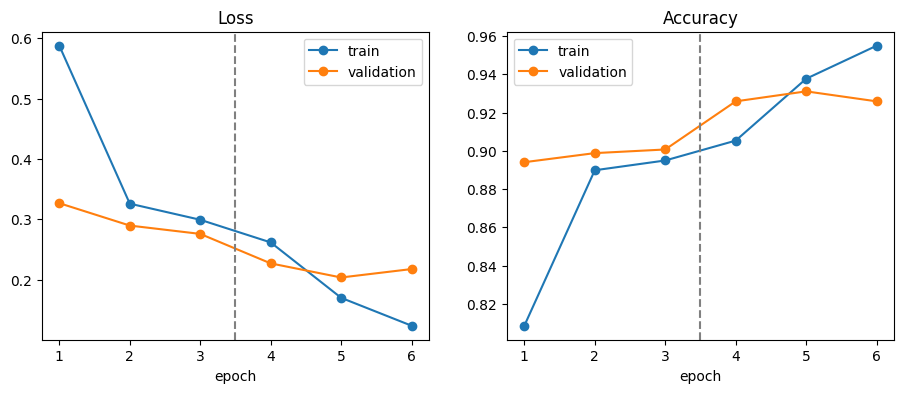

In [15]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')    # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

# Part 5:

## 1. Trainable Parameters
After unfreezing layer4, **8,396,806** parameters were trainable (8,393,728 in layer4 + 3,078 in the head). That is about 75% of the network, so layer4 holds roughly three quarters of all parameters.

## 2. Validation Accuracy per Epoch
| Epoch | Phase | Train loss | Train acc | Val loss | Val acc |
|---|---|---|---|---|---|
| 1 | feature extraction | 0.588 | 0.809 | 0.327 | 0.894 |
| 2 | feature extraction | 0.326 | 0.890 | 0.290 | 0.899 |
| 3 | feature extraction | 0.299 | 0.895 | 0.276 | 0.901 |
| 4 | fine-tuning | 0.262 | 0.905 | 0.227 | 0.926 |
| 5 | fine-tuning | 0.170 | 0.938 | 0.204 | 0.931 |
| 6 | fine-tuning | 0.124 | 0.955 | 0.218 | 0.926 |

## 3. Did Fine-Tuning Improve Accuracy?
Yes. Best validation accuracy rose from **0.901** (feature extraction) to **0.931** (fine-tuning, epoch 5), an improvement of **3.0 percentage points**. Accuracy jumped in the first fine-tuning epoch (0.901 → 0.926), peaked at 0.931 in epoch 5, and slipped back to 0.926 in epoch 6.

## 4. What the Curves Show
- **Loss:** training loss fell steadily in both phases (0.588 → 0.124). Validation loss fell from 0.327 to 0.276 during feature extraction, dropped to 0.204 by epoch 5 after fine-tuning started, then rose slightly to 0.218 in epoch 6.
- **Accuracy:** both curves rose, with a visible step up after the dashed line where layer4 was unfrozen. The training curve crosses the validation curve between epochs 4 and 5.

## 5. Is There Overfitting?
Yes, a mild sign appears in epoch 6. Training loss kept falling (0.170 → 0.124) while validation loss rose (0.204 → 0.218) and validation accuracy dropped (0.931 → 0.926). The model was starting to memorise the augmented training images. `fit()` kept the weights from epoch 5, the best validation epoch, so the saved model is not affected, but more epochs would probably make it worse.

## 6. Why Training Accuracy Can Be Lower Than Validation Accuracy
In epochs 1 to 4, training accuracy was lower than validation accuracy (for example 0.895 vs 0.901 in epoch 3, and 0.905 vs 0.926 in epoch 4). Training images are randomly cropped, flipped, and colour-jittered, which makes them harder, while validation images are clean. Training accuracy is also averaged over the whole epoch while the weights are still improving. The curves cross between epochs 4 and 5, when training accuracy (0.938) passes validation accuracy (0.931), because fine-tuning layer4 gave the model enough capacity to fit the augmented images.

Test accuracy: 0.935
              precision    recall  f1-score   support

   buildings      0.954     0.899     0.926       437
      forest      0.994     0.987     0.990       474
     glacier      0.921     0.870     0.895       553
    mountain      0.884     0.918     0.901       525
         sea      0.945     0.980     0.962       510
      street      0.923     0.960     0.941       501

    accuracy                          0.935      3000
   macro avg      0.937     0.936     0.936      3000
weighted avg      0.935     0.935     0.935      3000



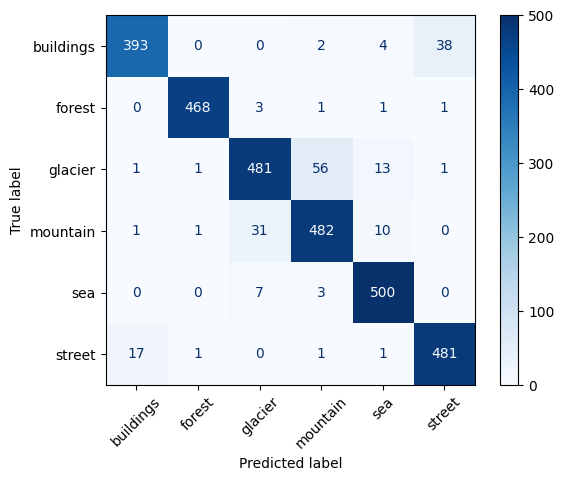

In [16]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

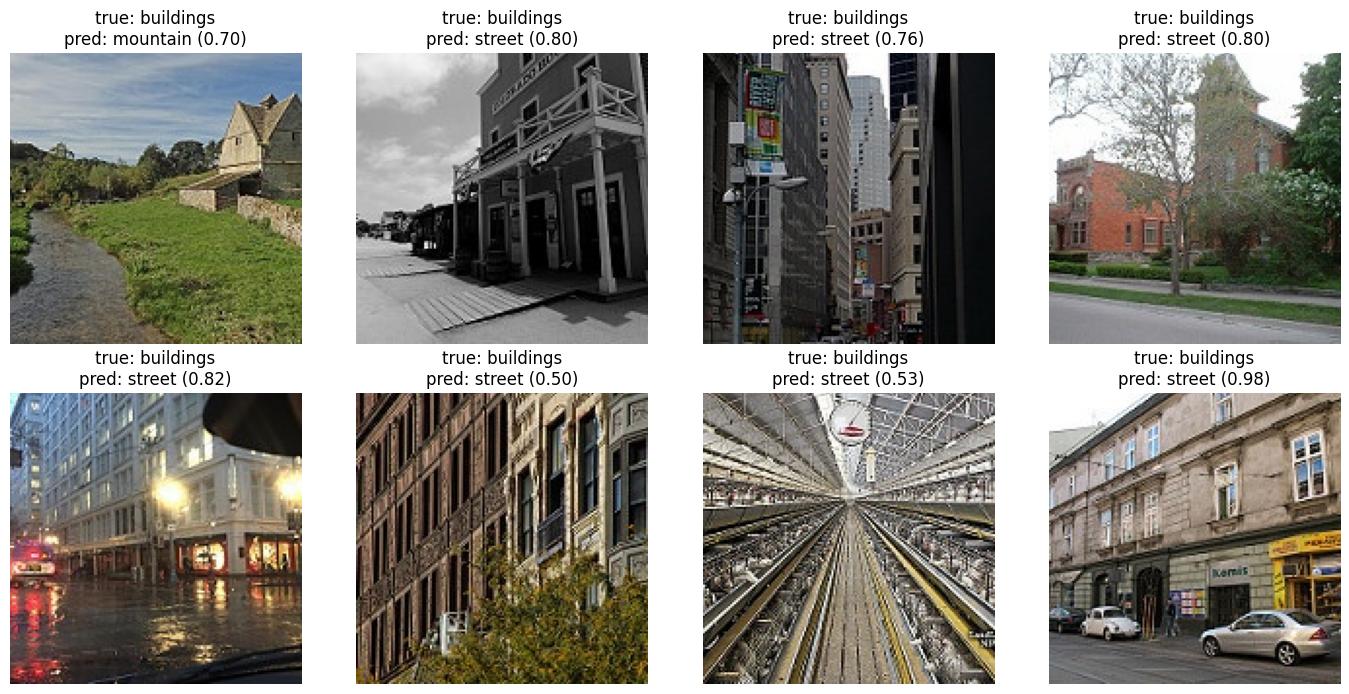

In [17]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

In [18]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   7.95   probability 1.000
forest     logit  -9.32   probability 0.000
glacier    logit  -4.66   probability 0.000
mountain   logit  -4.96   probability 0.000
sea        logit  -4.71   probability 0.000
street     logit  -3.45   probability 0.000


# Part 6:

## 1. Test Accuracy
The test set was used once. **Test accuracy: 0.935** (2,805 of 3,000 correct), close to the best validation accuracy (0.931), so the model generalises well.

## 2. Two Weakest Classes by Recall
| Class | Recall |
|---|---|
| glacier | **0.870** |
| buildings | **0.899** |

The strongest classes were forest (0.987) and sea (0.980).

## 3. Most Confused Pair
**Glacier and mountain.** 56 glacier images were predicted as mountain and 31 mountain images as glacier, 87 errors in total. The second most confused pair was buildings and street (38 + 17 = 55 errors).

## 4. Was My Part 1 Prediction Right?
Yes. In Part 1 I predicted that glacier and mountain would be confused the most, because both show snow, rock, and sky, and the confusion matrix confirms it.

## 5. Error Gallery
The gallery shows the first 8 wrong predictions in test-set order. Because the test folders are sorted by class, all 8 are true-class buildings (7 predicted as street, 1 as mountain), so the gallery does not show every kind of error. It matches the confusion matrix, where 38 buildings were predicted as street.

- **Error 1: true buildings, predicted mountain (0.70).** A small stone house beside a stream, surrounded by grass and hills. **The model was wrong, but the image is also ambiguous:** the building is a small part of the frame and the scenery dominates it. The low confidence (0.70) shows it was unsure.
- **Error 2: true buildings, predicted street (0.53).** The inside of a railway hall with tracks running into the distance. **The label is questionable:** it shows neither a typical building exterior nor a street, so it fits neither class well, and the model's low confidence (0.53) reflects that.

Most buildings-to-street errors involve images that contain both a building and a road or cars, so some labels are debatable.

## 6. Softmax on One Image
For the first test image (true class: buildings), the logits were 7.95 (buildings), -9.32 (forest), -4.66 (glacier), -4.96 (mountain), -4.71 (sea), and -3.45 (street). Softmax turned them into probabilities that sum to 1: buildings **1.000** and the other five about 0.000. The class with the largest logit gets the largest probability, and a gap of about 11 between the top two logits makes the model almost certain.

In [19]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


# Check Your Understanding

## 1. Why does a network without nonlinear activations collapse to a single linear layer?
Each layer computes W·x + b. Stacking two layers gives W2(W1·x + b1) + b2 = (W2·W1)·x + (W2·b1 + b2), which is again of the form W·x + b. Any number of linear layers reduces to one linear layer, so the network could only learn linear decision boundaries. A nonlinearity such as ReLU between layers prevents this collapse.

## 2. For logits [3, 1, 0], what probability does softmax give the first class?
- e^3 = 20.086, e^1 = 2.718, e^0 = 1
- Sum = 20.086 + 2.718 + 1 = 23.804
- P(first class) = 20.086 / 23.804 = **0.844**

## 3. Parameters of a 3x3 convolution from 64 to 128 channels
(K × K × C_in + 1) × C_out = (3 × 3 × 64 + 1) × 128 = 577 × 128 = **73,856**

## 4. Output size for a 56x56 input, 3x3 convolution, padding 1, stride 2
(W − K + 2P) / S + 1 = (56 − 3 + 2) / 2 + 1 = 27.5 + 1. Rounding the division down gives 27 + 1 = **28**, so the output is **28 x 28**.

## 5. Why does a residual (skip) connection help gradients reach the early layers?
A residual block computes y = x + F(x), so its derivative is 1 + dF/dx. The constant 1 gives the gradient a direct path backward that is not multiplied by many small weights or activation derivatives. This keeps the gradient from shrinking toward zero in deep networks, so early layers still receive a useful learning signal.

## 6. When would you train a CNN from scratch instead of using transfer learning?
When the images are very different from ImageNet photos (for example medical scans, spectrograms, or multispectral satellite data) and a large labeled dataset is available. It also makes sense when the pretrained model is too large for the target device and a smaller custom architecture is needed.